In [1]:
import jax_sn as jsn
%load_ext autoreload
%autoreload 2
import jax_sbgeom
from jax_sbgeom.flux_surfaces import ToroidalExtent
from jax_sbgeom.jax_utils import mesh_to_pyvista_mesh
import jax.numpy as jnp
import numpy as onp
from typing import Tuple
import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)

import pyvista as pv

def remove_zeros(array):
    a = onp.array(array)
    a[onp.abs(a) < 1e-14] = 0.0
    return a

from jax_sn.domain.geometric_domain import GeometricDomain, TopologicalSortedAngle
from jax_sn.solution_domain.solution_domain import FEMMatrices
from jax_sn.domain.geometric_domain import CrossSectionData
from jax_sn.source import Source
from typing import List
from jax_sn.tools.mesh_tools import _pad_last_dimension
onp.set_printoptions(linewidth = 200)

In [2]:
#flux_surface     =  jax_sbgeom.flux_surfaces.FluxSurface.from_hdf5("/home/tbogaarts/stellarator_paper/base_data/vmecs/helias5_vmec.nc4")
#s_mesh           = jnp.linspace(0, 1, 10)
#tetra_mesh       =  jax_sbgeom.flux_surfaces.flux_surface_meshing.mesh_tetrahedra(flux_surface, s_mesh, ToroidalExtent.half_module(flux_surface), 50,60)
#face_template    = jsn.tools.mesh_tools._face_template(tetra_mesh[1].shape[1])
#geometric_domain = jsn.domain.GeometricDomain.from_mesh(tetra_mesh, face_template)
#quadrature_set   = jsn.quadrature_set.tn.create_tn_quadrature_set(4)
#pol_mesh         = jax_sbgeom.flux_surfaces.flux_surface_meshing.mesh_poloidal_plane(flux_surface, jnp.linspace(0,1,10)**2, 0.52,  20)
#tri_face_template = jsn.tools.mesh_tools._face_template(pol_mesh[1].shape[1])
#pol_domain        = jsn.domain.GeometricDomain.from_mesh(pol_mesh, tri_face_template)


In [3]:
from finite_elements.test_finite_elements import _get_element_jsn

In [4]:

from basix import ElementFamily, LagrangeVariant
import basix
from jax_sn.solution_domain.basix_fem import BasixLagrangianSimplex, _create_face_quadrature_on_face, _map_simplex_point_to_different_permutation, _map_face_points_to_reference_cell
from jax_sn.tools.permutation_tools import _obtain_permutation, _indices_to_permutation_number
import jax_sn
degree = 3
lasimp = BasixLagrangianSimplex(1,3)
lasimp.n_vertices_per_face(0)

3

In [5]:
from finite_elements.test_transport_operator import setup_all_sb

lagrangian_element, domain, angle, toposort, femmatrices, precomputed_data, sweep_array, cross_sections, source, expected_values  = setup_all_sb(1,4)

In [6]:
from jax_sn.solution_domain.transport_operator import transport_inverse_sweep_complete_vmap_fori

In [7]:
def create_cartesian_domain(dimension : int, region_size_res : List[List[Tuple]], cross_sections_regions : List[float], source_regions : List[float], inhomogeneity_direction : int):
    assert len(region_size_res) == dimension, f"Regions size and resolution must be specified for all dimensions. Dimension: {dimension}, provided: {len(region_size_res)}"
    assert len(region_size_res[inhomogeneity_direction]) == len(cross_sections_regions) == len(source_regions),\
          f"Number of regions in inhomogeneity direction must match number of cross sections and sources. Provided: {len(region_size_res[inhomogeneity_direction])} sizes & resolutions, {len(cross_sections_regions)} cross sections, {len(source_regions)} sources."
    
    nodes = []
    for dim_i in range(len(region_size_res)):
        assert all([isinstance(x, List) or isinstance(x, Tuple) and len(x) == 2 for x in region_size_res[dim_i]]), f"Each entry in region_size_res must be a list of tuples (size, resolution). Provided: {region_size_res[dim_i]}"
        regions_dim   = region_size_res[dim_i]
        n_regions_dim = len(region_size_res[dim_i])        
        cumsum_nodes  = jnp.concatenate([jnp.array([0]), jnp.cumsum(jnp.array([sz for sz, res in regions_dim]))])        
        nodes.append(jnp.concatenate([jnp.linspace(cumsum_nodes[i], cumsum_nodes[i+1], region_size_res[dim_i][i][1], endpoint=False) for i in range(n_regions_dim)] + [jnp.array([cumsum_nodes[-1]])]))

    meshgrid = jnp.meshgrid(*nodes, indexing='ij')

    if dimension == 1:
        vertices = meshgrid[0].reshape(-1,1)
        connectivity = jnp.array([[i, i+1] for i in range(vertices.shape[0]-1)])
    elif dimension == 2:
        vertices  = jnp.stack(meshgrid, axis=-1).reshape(-1,2) # (n_points, 2) [implicit shape (n_x, n_y, 2)]
        connectivity = jax_sbgeom.flux_surfaces.flux_surface_meshing._build_open_triangle_surface(nodes[0].shape[0], nodes[1].shape[0], True)
    elif dimension == 3:
        vertices  = jnp.stack(meshgrid, axis=-1).reshape(-1,3) # (n_points, 3) [implicit shape (n_x, n_y, n_z, 3)]
        connectivity = jax_sbgeom.flux_surfaces.flux_surface_meshing._build_open_tetrahedral_mesh(nodes[0].shape[0], nodes[1].shape[0], nodes[2].shape[0], True)
    return vertices, connectivity
    
    
        
        

#create_cartesian_domain(3, [[(0.7,5), (0.3,3)], [(0.2,1), (5,4), (0.3, 2)], [(0.1,2), (4,3), (0.2,3)]], cross_sections_regions=[1.0,2.0], source_regions=[1.0, 2.0], inhomogeneity_direction=0)
vertices, connectivity = create_cartesian_domain(2, [[(0.7,5), (0.3,3)], [(0.2,1), (5,4), (0.3, 2)]], cross_sections_regions=[1.0,2.0], source_regions=[1.0, 2.0], inhomogeneity_direction=0)
vertices, connectivity = create_cartesian_domain(1, [[(0.7,5), (0.3,3)]], cross_sections_regions=[1.0,2.0], source_regions=[1.0, 2.0], inhomogeneity_direction=0)


In [29]:
from finite_elements.test_transport_operator import _verts_conn_from_sb
_verts_conn_from_sb(3,1)[1][0:200]

Array([[ 0, 16,  4,  1],
       [ 4,  1, 17,  5],
       [ 4,  1, 17, 16],
       [ 4, 17, 16, 20],
       [ 5, 17, 21, 20],
       [ 4, 17, 20,  5],
       [ 1, 17,  5,  2],
       [ 5,  2, 18,  6],
       [ 5,  2, 18, 17],
       [ 5, 18, 17, 21],
       [ 6, 18, 22, 21],
       [ 5, 18, 21,  6],
       [ 2, 18,  6,  3],
       [ 6,  3, 19,  7],
       [ 6,  3, 19, 18],
       [ 6, 19, 18, 22],
       [ 7, 19, 23, 22],
       [ 6, 19, 22,  7],
       [ 4, 20,  8,  5],
       [ 8,  5, 21,  9],
       [ 8,  5, 21, 20],
       [ 8, 21, 20, 24],
       [ 9, 21, 25, 24],
       [ 8, 21, 24,  9],
       [ 5, 21,  9,  6],
       [ 9,  6, 22, 10],
       [ 9,  6, 22, 21],
       [ 9, 22, 21, 25],
       [10, 22, 26, 25],
       [ 9, 22, 25, 10],
       [ 6, 22, 10,  7],
       [10,  7, 23, 11],
       [10,  7, 23, 22],
       [10, 23, 22, 26],
       [11, 23, 27, 26],
       [10, 23, 26, 11],
       [ 8, 24, 12,  9],
       [12,  9, 25, 13],
       [12,  9, 25, 24],
       [12, 25, 24, 28],


In [32]:
jax_sbgeom.flux_surfaces.flux_surface_meshing._tetrahedral_open_cube(8,4,4)[0:20]

Array([[ 0, 16, 17, 20],
       [ 0, 17, 20, 21],
       [ 0,  4, 21, 20],
       [ 0,  1, 17, 21],
       [ 0,  1,  4, 21],
       [ 5,  1,  4, 21],
       [16, 32, 33, 36],
       [16, 33, 36, 37],
       [16, 20, 37, 36],
       [16, 17, 33, 37],
       [16, 17, 20, 37],
       [21, 17, 20, 37],
       [32, 48, 49, 52],
       [32, 49, 52, 53],
       [32, 36, 53, 52],
       [32, 33, 49, 53],
       [32, 33, 36, 53],
       [37, 33, 36, 53],
       [48, 64, 65, 68],
       [48, 65, 68, 69]], dtype=int64)

In [16]:
x = jnp.linspace(0,1,10)
y = jnp.linspace(0,2,15)
z = jnp.linspace(0,3,12)

xx, yy, zz= jnp.meshgrid(x,y,z, indexing='ij')
points = jnp.stack([xx.reshape(-1), yy.reshape(-1), zz.reshape(-1)], axis=-1)

result = jax_sbgeom.flux_surfaces.flux_surface_meshing._tetrahedral_open_cube(x.shape[0], y.shape[0], z.shape[0])



In [17]:
plotter = pv.Plotter()
mesh = mesh_to_pyvista_mesh(_pad_last_dimension(points), result.reshape(-1,4))
plotter.add_mesh(mesh, scalars = onp.arange(result.reshape(-1,4).shape[0]), show_edges=True, opacity=1.0)    
plotter.show()

Widget(value='<iframe src="http://localhost:43765/index.html?ui=P_0x6ff9ec158920_3&reconnect=auto" class="pyvi…

In [44]:
plotter = pv.Plotter()
mesh = mesh_to_pyvista_mesh(_pad_last_dimension(vertices), connectivity)
plotter.add_mesh(mesh, scalars = onp.arange(connectivity.shape[0]), show_edges=True, opacity=1.0)    
plotter.show()

Widget(value='<iframe src="http://localhost:44985/index.html?ui=P_0x7d8489308800_10&reconnect=auto" class="pyv…

In [494]:
q_i = 1
s_i = 1
cross_sections_flat = CrossSectionData(jnp.ones_like(cross_sections.total) * s_i)
source_flat         = Source(jnp.ones_like(source.source_values) * q_i)

In [495]:
result = transport_inverse_sweep_complete_vmap_fori(femmatrices, domain, toposort, cross_sections_flat, precomputed_data, source_flat, sweep_array )

In [502]:
onp.set_printoptions(linewidth=200)

In [503]:
aabb_min = jnp.min(domain.vertices, axis=0)
aabb_max = jnp.max(domain.vertices, axis=0)
points = jnp.linspace(aabb_min[0], aabb_max[0], 370)
points = jnp.stack([points] + [jnp.zeros_like(points) ] * (lagrangian_element.dimension - 1), axis=-1)

element_indices = domain.containing_cell(points)

In [504]:
import pyvista as pv
from jax_sn.tools.mesh_tools import _pad_last_dimension
plotter = pv.Plotter()
mesh = mesh_to_pyvista_mesh(_pad_last_dimension(domain.vertices), domain.connectivity)
plotter.add_mesh(mesh, show_edges=True, opacity=1.0)    
plotter.show()

Widget(value='<iframe src="http://localhost:38183/index.html?ui=P_0x7910a5238620_13&reconnect=auto" class="pyv…

In [508]:
interpolated = lagrangian_element.interpolate_from_real_coordinate(points, element_indices, domain, precomputed_data, result)

In [544]:
def analytical(x, sigma, q, mu):
    if mu > 0:
        return q / sigma * (1 - jnp.exp(- sigma * x / mu))
    else:
        return q / sigma * (1 - jnp.exp(- sigma * (1.0 - x) / jnp.abs(mu)))

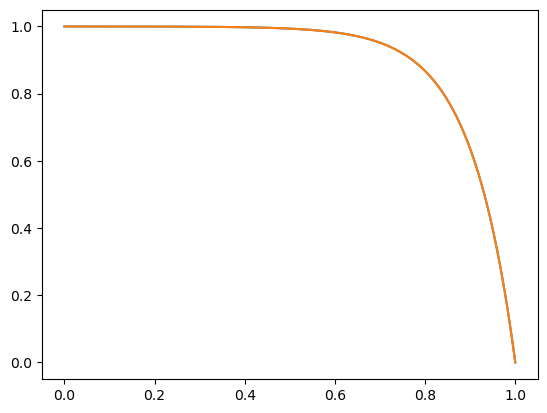

In [545]:
import matplotlib.pyplot as plt
plt.plot(points[:,0], interpolated)
plt.plot(points[:,0], analytical(points[:,0], s_i, q_i, angle[0]))